# CS 463 Project — Neural Networks (one state per run)

Trains the MLP and the LSTM sequence model for **one state**, using the same
training rows, early-stopping dates and rules as `03_Modeling.ipynb`. Run
`03_Modeling.ipynb` for the state first; this notebook adds its forecasts to
the state's results files.

```
STATE=TX jupyter nbconvert --to notebook --execute 04_Neural_Networks.ipynb --output 04_Neural_Networks_TX.ipynb
```

**Shared setup (`src/neural.py`):**

- **Series embedding:** each product-store series gets a learned 16-number
  vector. Series first seen after training use the average embedding.
- **Inputs:** count-like features are log-transformed (`log(1 + x)`), then
  standardized and clipped to ±10 standard deviations.
- **Output:** log expected sales; the forecast is `exp(output)`, capped at
  `exp(8)` ≈ 3,000 units.
- **Loss:** Poisson negative log-likelihood (suited to count data).
- **Optimizer:** Adam, learning rate 0.001, batch size 4,096, up to 8 epochs,
  keeping the epoch with the lowest early-stopping loss (patience 2).

In [1]:
import os
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import config
from src import data_prep as dp
from src import neural as nnm

STATE = os.environ.get("STATE", "CA")
assert STATE in config.STATES, f"unknown state {STATE}"

MODEL_DIR = config.MODELS_DIR / STATE
RESULT_DIR = config.RESULTS_DIR / STATE
assert (RESULT_DIR / "validation_predictions.parquet").exists(), "run 03_Modeling.ipynb for this state first"

MLP_SAMPLE = 3_000_000
LSTM_SAMPLE = 1_000_000
STOP_SAMPLE = 500_000
SEQ_LEN = 28

rng = np.random.default_rng(config.SEED)
torch.manual_seed(config.SEED)
print("State:", STATE)

State: TX


## 1. Data

Same clean training rows and early-stopping cutoff (last 10% of training
dates) as `03_Modeling.ipynb`. Random samples keep training time and memory
manageable.

In [2]:
features = dp.load_features(STATE)
columns = ["store_id", "item_id", "date", "target_sales", "is_suspected_stockout"] + features

train = dp.load_split(STATE, "train", columns)
train = train[train["is_suspected_stockout"] == 0].reset_index(drop=True)
validation = dp.load_split(STATE, "validation", columns)

stop_cutoff = train["date"].quantile(0.9)
fit_idx = np.flatnonzero((train["date"] < stop_cutoff).to_numpy())
stop_idx = np.flatnonzero((train["date"] >= stop_cutoff).to_numpy())

mlp_rows = rng.choice(fit_idx, min(MLP_SAMPLE, len(fit_idx)), replace=False)
lstm_rows = rng.choice(fit_idx, min(LSTM_SAMPLE, len(fit_idx)), replace=False)
stop_rows = rng.choice(stop_idx, min(STOP_SAMPLE, len(stop_idx)), replace=False)

prep = nnm.Preprocessor(features).fit(train.iloc[mlp_rows])

data = {}
for split, frame in [("fit", train.iloc[mlp_rows]), ("lstm_fit", train.iloc[lstm_rows]),
                     ("stop", train.iloc[stop_rows]), ("val", validation)]:
    X, series = prep.transform(frame)
    data[split] = {"X": X, "series": series, "y": frame["target_sales"].to_numpy(np.float32), "frame": frame}

print(f"MLP rows: {len(mlp_rows):,} | LSTM rows: {len(lstm_rows):,} | early-stopping rows: {len(stop_rows):,} | validation rows: {len(validation):,}")
print("Product-store series with embeddings:", len(prep.series_ids))

MLP rows: 3,000,000 | LSTM rows: 1,000,000 | early-stopping rows: 500,000 | validation rows: 2,500,376
Product-store series with embeddings: 8273


## 2. MLP (multilayer perceptron)

| Layer | Details |
|---|---|
| Input | all features + 16-dim series embedding |
| Hidden 1 | 128 units, ReLU, dropout 0.1 |
| Hidden 2 | 64 units, ReLU |
| Output | 1 unit (log expected sales) |

In [3]:
def mlp_batch(split, idx):
    d = data["fit" if split == "fit" else split]
    return (torch.from_numpy(d["X"][idx]), torch.from_numpy(d["series"][idx])), torch.from_numpy(d["y"][idx])


start = time.time()
mlp = nnm.DemandMLP(len(features), len(prep.series_ids))
mlp, mlp_history = nnm.fit_network(mlp, mlp_batch, len(mlp_rows), len(stop_rows))
mlp = nnm.set_unknown_embedding(mlp)
mlp_seconds = time.time() - start

mlp_val = nnm.predict_network(mlp, mlp_batch, "val", len(validation))
torch.save(mlp.state_dict(), MODEL_DIR / "mlp.pt")
print(f"Trained in {mlp_seconds:.0f}s; early-stopping loss by epoch:", np.round(mlp_history, 4))

Trained in 43s; early-stopping loss by epoch: [-0.5451 -0.5526 -0.5518 -0.557  -0.559  -0.55   -0.5577]


## 3. LSTM sequence model (RNN)

Instead of the hand-made sales-history features, the LSTM reads the raw
daily sales known on order day (the 28 days ending 7 days before the target
day) and learns its own summary of recent demand.

| Part | Details |
|---|---|
| Sequence input | 28 days of `log(1 + sales)`, days t−34 to t−7 |
| LSTM | 1 layer, 64 hidden units |
| Other inputs | known-in-advance features (price, calendar, events, department, store, product age) + 16-dim series embedding |
| Head | 64 units, ReLU → 1 output (log expected sales) |

In [4]:
history = nnm.SalesHistory(STATE)
known_positions = [features.index(c) for c in features if c not in nnm.HISTORY_FEATURES]
known_columns = [features[i] for i in known_positions]

lstm_data = {}
for split in ["lstm_fit", "stop", "val"]:
    rows, days = history.rows_and_days(data[split]["frame"])
    assert (days - config.HORIZON - SEQ_LEN + 1 >= 0).all(), "history window starts before the first day"
    lstm_data[split] = {"rows": rows, "days": days, "known": data[split]["X"][:, known_positions],
                        "series": data[split]["series"], "y": data[split]["y"]}


def lstm_batch(split, idx):
    d = lstm_data["lstm_fit" if split == "fit" else split]
    sequence = history.windows(d["rows"][idx], d["days"][idx], SEQ_LEN)
    inputs = (torch.from_numpy(sequence), torch.from_numpy(d["known"][idx]), torch.from_numpy(d["series"][idx]))
    return inputs, torch.from_numpy(d["y"][idx])


start = time.time()
lstm = nnm.DemandLSTM(len(known_columns), len(prep.series_ids))
lstm, lstm_history = nnm.fit_network(lstm, lstm_batch, len(lstm_rows), len(stop_rows))
lstm = nnm.set_unknown_embedding(lstm)
lstm_seconds = time.time() - start

lstm_val = nnm.predict_network(lstm, lstm_batch, "val", len(validation))
torch.save(lstm.state_dict(), MODEL_DIR / "lstm.pt")
print(f"Trained in {lstm_seconds:.0f}s; early-stopping loss by epoch:", np.round(lstm_history, 4))

Trained in 332s; early-stopping loss by epoch: [-0.4787 -0.5003 -0.5162 -0.5207 -0.5187 -0.5258 -0.5272 -0.5308]


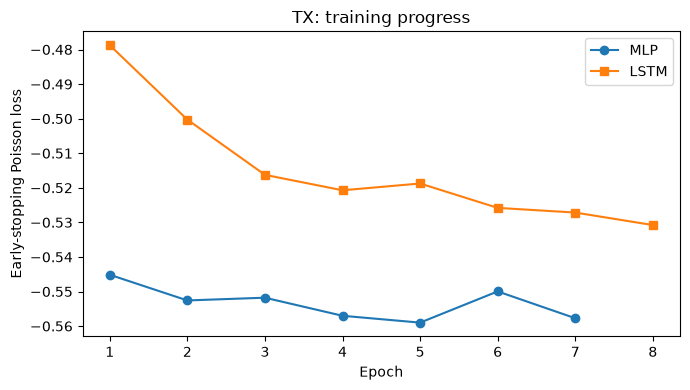

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(mlp_history) + 1), mlp_history, marker="o", label="MLP")
ax.plot(range(1, len(lstm_history) + 1), lstm_history, marker="s", label="LSTM")
ax.set_xlabel("Epoch")
ax.set_ylabel("Early-stopping Poisson loss")
ax.set_title(f"{STATE}: training progress")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Save models and forecasts

In [6]:
joblib.dump({"preprocessor": prep, "known_columns": known_columns, "seq_len": SEQ_LEN},
            MODEL_DIR / "nn_preprocessing.joblib")

predictions = pd.read_parquet(RESULT_DIR / "validation_predictions.parquet")
assert len(predictions) == len(validation)
predictions["MLP"] = np.maximum(0, mlp_val).astype(np.float32)
predictions["LSTM"] = np.maximum(0, lstm_val).astype(np.float32)
predictions.to_parquet(RESULT_DIR / "validation_predictions.parquet", index=False)

summary = pd.read_csv(RESULT_DIR / "model_summary.csv")
summary = summary[~summary["model"].isin(["MLP", "LSTM"])]
summary = pd.concat([summary, pd.DataFrame([
    {"model": "MLP", "hyperparameters": f"128-64 ReLU, dropout 0.1, {len(mlp_history)} epochs",
     "training rows": len(mlp_rows), "train time (s)": round(mlp_seconds, 1)},
    {"model": "LSTM", "hyperparameters": f"{SEQ_LEN}-day sequence, 64 hidden, {len(lstm_history)} epochs",
     "training rows": len(lstm_rows), "train time (s)": round(lstm_seconds, 1)},
])], ignore_index=True)
summary.to_csv(RESULT_DIR / "model_summary.csv", index=False)
summary.style.format({"training rows": "{:,}"})

,model,hyperparameters,training rows,train time (s)
0,Baseline: last week,none,0,0.000000
1,Baseline: 28-day average,none,0,0.000000
2,Linear Regression,none,"2,000,000",2.600000
3,Ridge (alpha=10),alpha=10,"2,000,000",0.800000
4,LASSO (alpha=0.001),alpha=0.001,"2,000,000",12.800000
5,Random Forest,"100 trees, depth 14, min leaf 20, 50% features","1,000,000",67.900000
6,XGBoost (squared error),221 trees,"6,030,201",32.700000
7,"XGBoost (Tweedie, p=1.3)","p=1.3, 307 trees","6,030,201",60.400000
8,Hurdle model (XGBoost + XGBoost),"stage 1: 420 trees, stage 2: 577 trees","6,030,201",122.900000
9,MLP,"128-64 ReLU, dropout 0.1, 7 epochs","3,000,000",42.600000
